# P4: Project Synthesis
**DSA 405 · Fall 2026 · Project Milestone 4**

Name: Sharmila Shirolkar | Unity ID: sshirol
Repository: https://github.com/sharmila224/dsa405-project

**What this project is, and what it found.** This project combines Backblaze Drive Stats
(datacenter drive failure and health data) with Wikipedia drive-specification articles to
study hard-drive reliability. Along the way it found that the two public sources share no
usable common key, so the planned per-model join was impossible and the data supports only a
manufacturer-and-capacity-class join. At that grain, Wikipedia documents about a quarter of
the fleet. The core failure question cannot yet be answered because a single daily snapshot
contains only one failed drive; that is documented honestly below.

This notebook runs top to bottom on a restarted kernel, from the raw data to the final
figures, and also contains the written report (sections 1 to 9).



## 1. Data motivation

**The question.** Do certain hard-drive manufacturers and models fail earlier under real
datacenter workloads, and can drives heading toward failure be flagged in advance from their
SMART health readings?

**Why I chose it.** A drive failure is costly twice, the replacement and the risk to the data
on it. If failure rates differ by model, or if a small set of SMART attributes rises before a
failure, that changes what a storage operator buys and when they replace hardware.

**How the question changed once I had the data.** Two things shifted. First, I planned to join
Backblaze to Wikipedia on the exact drive-model string, but Backblaze uses internal model codes
(for example `ST16000NM001G`) that never appear in Wikipedia, so I moved to a manufacturer and
capacity-class join, the fallback I named in P1. Second, I reduced the data to a single daily
snapshot, which contains only one failed drive. That is far too few to estimate failure rates
or test the SMART early-warning idea, so this milestone focuses on building and verifying a
correct integration pipeline and on honestly characterizing what the combined data can and
cannot support. The failure analysis itself needs many quarters of drive-days.

In [1]:
import os, re, io, time, requests, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

os.makedirs("data/raw", exist_ok=True)
RAW_DIR = "data/raw"
HEADERS = {"User-Agent": "DSA405-student-coursework (NC State; teaching exercise)"}
pd.set_option("display.width", 160)
print("pandas", pd.__version__, "| ready")

pandas 2.2.3 | ready


## 2. Sources, provenance & terms

**Source 1: Backblaze Drive Stats (download).**
- Producer: Backblaze, Inc., published openly since 2013.
- How collected: Backblaze records a daily snapshot of every powered-on drive in its own
  datacenters (date, serial number, model, capacity, a failure flag, and SMART attributes).
- Coverage: this project uses one daily snapshot (2026-01-01) reduced to the columns it needs,
  338,760 drive records.
- License/terms: free to use if you cite Backblaze and do not sell the data itself. Cited here.
- How accessed: a reduced gzip CSV is stored in this repo under `data/raw/` and read over the web.

**Source 2: Wikipedia drive-specification articles (web, scraped).**
- Producer: Wikipedia contributors / Wikimedia Foundation.
- How collected: the notebook fetches manufacturer and product-line articles with `requests`,
  using an honest User-Agent, a one-second rate limit, and on-disk caching, and parses the drive
  capacities from each page.
- Coverage: capacities documented per manufacturer; parsed to 25 manufacturer-and-capacity rows.
- License: CC BY-SA. Attributed here.
- How accessed: logged out, article (`/wiki/`) paths only, which Wikipedia's robots.txt permits.

In [2]:
# Source 1: load the reduced Backblaze snapshot from the repo (raw file is never modified).
BB_URL = "https://raw.githubusercontent.com/sharmila224/dsa405-project/main/data/raw/backblaze_extract.csv.gz"
raw = pd.read_csv(BB_URL, dtype={"serial_number": str, "model": str})
print("raw shape:", raw.shape)
raw.head()

raw shape: (338760, 10)


,date,serial_number,model,capacity_bytes,failure,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw
0,2026-01-01,000a43e7dee60010,DELLBOSS VD,480036847616,0,NaN,NaN,NaN,NaN,NaN
1,2026-01-01,00ac486b9bec0010,DELLBOSS VD,480036847616,0,NaN,NaN,NaN,NaN,NaN
2,2026-01-01,01b776caeb6a0010,DELLBOSS VD,480036847616,0,NaN,NaN,NaN,NaN,NaN
3,2026-01-01,02308a3415be0010,DELLBOSS VD,480036847616,0,NaN,NaN,NaN,NaN,NaN
4,2026-01-01,0394cd7bc5d00010,DELLBOSS VD,480036847616,0,NaN,NaN,NaN,NaN,NaN


## 3. Data dictionary & metadata (final)

| Variable | Type | Units | Valid range | Missingness | Notes |
|---|---|---|---|---|---|
| date | datetime | calendar date | 2026-01-01 | 0 | One snapshot; parsed from text to datetime. |
| serial_number | string | n/a | manufacturer serial | 0 | Identifies the drive, not a person. All 338,760 unique. |
| model | string | n/a | e.g. ST16000NM001G | 0 | 78 model codes; manufacturer is in the prefix. |
| capacity_bytes | int | bytes | > 0 | 0 | 240 GB to 26 TB observed. |
| failure | int | flag | {0, 1} | 0 | 1 on the day a drive fails; only 1 failure in this snapshot. |
| smart_5_raw | float | count | >= 0 | 0.7% | Reallocated sectors. |
| smart_187_raw | float | count | >= 0 | 66.4% | Reported uncorrectable errors; many drives do not report it. |
| smart_188_raw | float | count | >= 0 | 66.5% | Command timeout; packs several counters, so very large values are expected. |
| smart_197_raw | float | count | >= 0 | 2.5% | Current pending sectors. |
| smart_198_raw | float | count | >= 0 | 0.8% | Offline uncorrectable sectors. |
| manufacturer | string | n/a | {Seagate, Western Digital, Toshiba, HGST, Other} | 0 | Derived from the model prefix (P2). |
| capacity_tb | int | TB | 0 to 26 | 0 | capacity_bytes rounded to TB; the join key (P3). |
| wiki_capacity_documented | bool | flag | {True, False} | 0 | True if this manufacturer+capacity appears on Wikipedia (P3 join output). |

## 4. Data cleaning steps narrative

The Backblaze source is well curated: the P2 audit found no sentinel values, no duplicate
(date, serial) keys, a single date format, and no numbers stored as text. The cleaning is
therefore light and loses no rows. Three columns are derived and the SMART blanks are kept
as-is on purpose, because a blank means "not reported," which must stay distinct from a
reported zero. The next cell builds the clean table and prints the cleaning log and the row
and column accounting.

In [3]:
clean = raw.copy()
log = []
def record(col, change, count, why, lost):
    log.append({"#": len(log)+1, "Column": col, "Change made": change,
                "Rows/cells affected": int(count), "Why": why, "What is lost": lost})

rows_in = len(clean)

# 1. date text -> datetime
clean["date"] = pd.to_datetime(clean["date"], errors="coerce")
record("date", "Parsed text to datetime", rows_in,
       "Dates loaded as text cannot be sorted or differenced", "Nothing")

# 2. manufacturer from the model prefix (new column)
def manufacturer_of(m):
    m = str(m).upper()
    if m.startswith("ST"): return "Seagate"
    if m.startswith("WDC") or m.startswith("WD"): return "Western Digital"
    if m.startswith("TOSHIBA"): return "Toshiba"
    if m.startswith(("HGST", "HMS", "HUH")): return "HGST"
    return "Other"
clean["manufacturer"] = clean["model"].map(manufacturer_of)
record("manufacturer", "Derived from model prefix (new column)", rows_in,
       "The question asks about failure by manufacturer, not a raw column",
       "Nothing; model is kept")

# 3. capacity_tb from capacity_bytes (new column, the join key)
clean["capacity_tb"] = (clean["capacity_bytes"] / 1e12).round().astype(int)
record("capacity_tb", "Derived from capacity_bytes, rounded to TB (new column)", rows_in,
       "capacity_tb is the join key shared with the Wikipedia specs",
       "Nothing; capacity_bytes is kept")

# 4. SMART blanks: checked, not changed
for col in ["smart_187_raw", "smart_188_raw"]:
    record(col, "Checked, not changed", int(clean[col].isna().sum()),
           "Structural missingness: many models do not report this attribute, so blank = 'not reported', not an error",
           "Nothing; true NaN kept")
for col in ["smart_5_raw", "smart_197_raw", "smart_198_raw"]:
    record(col, "Checked, not changed", int(clean[col].isna().sum()),
           "Low-rate missingness left as true NaN so 'not reported' stays explicit", "Nothing")

rows_out = len(clean)
pd.set_option("display.max_colwidth", None)
print(pd.DataFrame(log).to_string(index=False))
print(f"\nrows in = {rows_in:,}   rows out = {rows_out:,}   (reconciles: {rows_in == rows_out})")
print(f"columns: raw {raw.shape[1]} + 2 derived = {clean.shape[1]}   (no rows or columns removed)")

 #        Column                                             Change made  Rows/cells affected                                                                                                       Why                    What is lost
 1          date                                 Parsed text to datetime               338760                                                      Dates loaded as text cannot be sorted or differenced                         Nothing
 2  manufacturer                  Derived from model prefix (new column)               338760                                         The question asks about failure by manufacturer, not a raw column          Nothing; model is kept
 3   capacity_tb Derived from capacity_bytes, rounded to TB (new column)               338760                                               capacity_tb is the join key shared with the Wikipedia specs Nothing; capacity_bytes is kept
 4 smart_187_raw                                    Checked, not changed

## 5. Integration & verification

**Acquisition of the web source.** The next cell scrapes the Wikipedia articles and parses the
drive capacities from each page. It is rate-limited, caches each page to `data/raw/`, and fails
loudly: a page that returns a non-200 status, times out, or has no capacity data is handled
explicitly, never silently.

In [4]:
WIKI_SOURCES = [
    ("Seagate",         "https://en.wikipedia.org/wiki/Seagate_Technology"),
    ("Seagate",         "https://en.wikipedia.org/wiki/Seagate_Barracuda"),
    ("Western Digital", "https://en.wikipedia.org/wiki/Western_Digital"),
    ("Western Digital", "https://en.wikipedia.org/wiki/Ultrastar"),
    ("HGST",            "https://en.wikipedia.org/wiki/Ultrastar"),
    ("HGST",            "https://en.wikipedia.org/wiki/HGST"),
    ("Toshiba",         "https://en.wikipedia.org/wiki/Toshiba"),
]

CACHE = {}
def fetch_html(url, delay=1.0):
    """Fetch a URL at most once per run: honest UA, timeout, cached to disk, raise on non-200."""
    if url in CACHE:
        print(f"  cached (memory): {url}"); return CACHE[url]
    slug = re.sub(r"[^A-Za-z0-9]+", "_", url.split("/wiki/")[-1])
    path = os.path.join(RAW_DIR, f"wiki_{slug}.html")
    if os.path.exists(path):
        print(f"  cached (disk): {path}")
        html = open(path, encoding="utf-8").read(); CACHE[url] = html; return html
    r = requests.get(url, headers=HEADERS, timeout=20); r.raise_for_status()
    html = r.text
    with open(path, "w", encoding="utf-8") as f: f.write(html)
    CACHE[url] = html; time.sleep(delay); return html

CAP_RE = re.compile(r"(?<!\d)(\d{1,2})\s*TB")
spec_rows, warnings = [], []
for manufacturer, url in WIKI_SOURCES:
    try:
        html = fetch_html(url)
    except requests.HTTPError as e:
        warnings.append(f"{url}: HTTP {e.response.status_code}, skipped"); continue
    except requests.RequestException as e:
        warnings.append(f"{url}: request failed ({type(e).__name__}), skipped"); continue
    text = BeautifulSoup(html, "html.parser").get_text(" ").replace("\xa0", " ")
    caps = {int(x) for x in CAP_RE.findall(text)}
    caps = {c for c in caps if 1 <= c <= 30}
    if not caps:
        warnings.append(f"{url}: no TB capacities found in page text"); continue
    for c in caps:
        spec_rows.append({"manufacturer": manufacturer, "capacity_tb": c,
                          "spec_source": url.split("/wiki/")[-1]})

specs_raw = pd.DataFrame(spec_rows)
if specs_raw.empty:
    raise RuntimeError("Wikipedia scrape produced no spec rows. Warnings: " + "; ".join(warnings))

specs = (specs_raw.drop_duplicates(["manufacturer", "capacity_tb"])
                  .assign(wiki_capacity_documented=True).reset_index(drop=True))
specs.to_csv(os.path.join(RAW_DIR, "wikipedia_specs.csv"), index=False)
print("spec rows (manufacturer x capacity_tb):", len(specs))
print("warnings:", warnings or "none")
specs.sort_values(["manufacturer", "capacity_tb"])

  cached (memory): https://en.wikipedia.org/wiki/Ultrastar
spec rows (manufacturer x capacity_tb): 25
warnings: ['https://en.wikipedia.org/wiki/Ultrastar: no TB capacities found in page text', 'https://en.wikipedia.org/wiki/Ultrastar: no TB capacities found in page text', 'https://en.wikipedia.org/wiki/Toshiba: no TB capacities found in page text']


,manufacturer,capacity_tb,spec_source,wiki_capacity_documented
24,HGST,6,HGST,True
22,HGST,8,HGST,True
23,HGST,10,HGST,True
0,Seagate,1,Seagate_Technology,True
1,Seagate,2,Seagate_Technology,True
2,Seagate,3,Seagate_Technology,True
3,Seagate,4,Seagate_Technology,True
4,Seagate,5,Seagate_Technology,True
5,Seagate,8,Seagate_Technology,True
12,Seagate,10,Seagate_Barracuda,True


**Join design.**

| | |
|---|---|
| Join key(s) | `manufacturer`, `capacity_tb` |
| Grain, left (Backblaze) | one row per drive (one daily snapshot) |
| Grain, right (Wikipedia) | one row per (manufacturer, capacity class) |
| Relationship | many-to-one (many drives to one spec row) |
| Expected rows after join | 338,760 (unchanged from the left table) |
| Join type and why | left join, to keep every drive even when its manufacturer+capacity is undocumented |
| Unmatched rows | kept; `wiki_capacity_documented` becomes False |

The code guards against both Week-6 failures: the left join prevents the inner-join "wreck"
(dropping unmatched drives), and `validate="many_to_one"` with a deduplicated right table
prevents the fan-out (multiplying drive rows). If my stated cardinality were wrong, `validate`
would raise instead of silently inflating the data.

In [5]:
specs_key = specs[["manufacturer", "capacity_tb", "wiki_capacity_documented"]]
N_EXPECTED = len(clean)
merged = clean.merge(specs_key, on=["manufacturer", "capacity_tb"], how="left", validate="many_to_one")
merged["wiki_capacity_documented"] = merged["wiki_capacity_documented"].eq(True)

match_rate = merged["wiki_capacity_documented"].mean()
print(f"drives: {len(clean):,}  |  merged rows: {len(merged):,}  (expected {N_EXPECTED:,})")
print(f"match rate (manufacturer+capacity documented on Wikipedia): {match_rate:.1%}")
merged[["model", "manufacturer", "capacity_tb", "failure", "wiki_capacity_documented"]].head()

drives: 338,760  |  merged rows: 338,760  (expected 338,760)
match rate (manufacturer+capacity documented on Wikipedia): 26.2%


,model,manufacturer,capacity_tb,failure,wiki_capacity_documented
0,DELLBOSS VD,Other,0,0,False
1,DELLBOSS VD,Other,0,0,False
2,DELLBOSS VD,Other,0,0,False
3,DELLBOSS VD,Other,0,0,False
4,DELLBOSS VD,Other,0,0,False


In [6]:
def verify(df, specs, n_expected):
    """Each check states an assumption; a non-empty list means an assumption broke."""
    fails = []
    if len(df) != n_expected: fails.append(f"row count {len(df)} != {n_expected}")                       # fan-out
    if df["serial_number"].nunique() != n_expected: fails.append("drives lost or duplicated in the join") # wreck/fan-out
    if specs.duplicated(["manufacturer", "capacity_tb"]).any(): fails.append("specs key not unique")       # fan-out root
    if not df["capacity_bytes"].gt(0).all(): fails.append("capacity_bytes <= 0 present")                   # value range
    if not set(df["failure"].dropna().unique()) <= {0, 1}: fails.append("failure outside {0,1}")           # value range
    if not set(df["manufacturer"].unique()) <= {"Seagate", "Western Digital", "Toshiba", "HGST", "Other"}:
        fails.append("unexpected manufacturer")                                                           # domain
    return fails

print("verification:", verify(merged, specs_key, N_EXPECTED) or "all checks passed")

# Prove the suite catches a real error: break a COPY (the real data is untouched).
broken = merged.copy()
broken.loc[broken.index[0], "capacity_bytes"] = -1
print("verify on a broken copy:", verify(broken, specs_key, N_EXPECTED))

verification: all checks passed
verify on a broken copy: ['capacity_bytes <= 0 present']


## 6. Findings

**What is known (supported directly by the data).** The snapshot holds 338,760 drives. The
fleet is dominated by two makers, Seagate and Toshiba, at roughly a third each, with Western
Digital next and HGST and a small "Other" group (DELLBOSS boot devices) behind. On the
integration side, Wikipedia documents only about a quarter of this fleet's manufacturer-and-
capacity combinations: Seagate is well covered, Western Digital and HGST are covered only
partly, and Toshiba, a third of the fleet, has no capacities listed on its page at all, so none
of its drives matched. The two figures below show both results from the live data.

**What is suspected or unknown.** Whether any manufacturer or model fails earlier than another
is unknown from this data. A single daily snapshot contains only one failed drive, which is far
too few to estimate a failure rate or to test whether SMART attributes rise before a failure.
I therefore make no claim about reliability by model; the pipeline is built and verified so that
this question can be answered later with multiple quarters of drive-days.

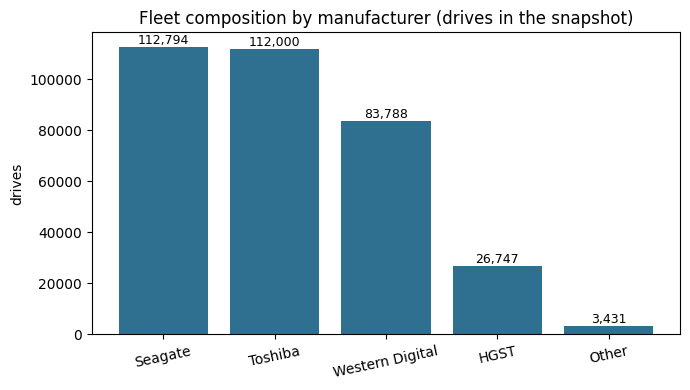

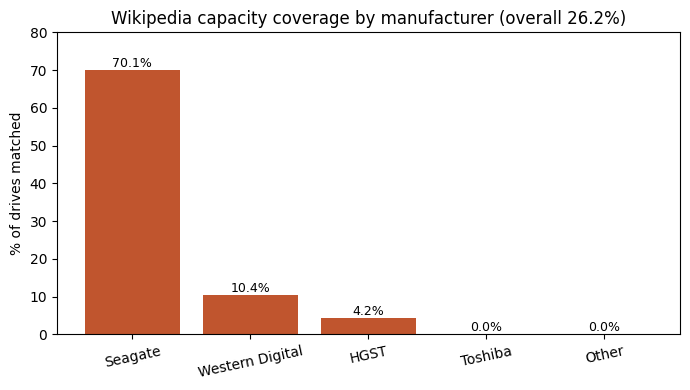

In [7]:
# Figure 1: fleet composition by manufacturer
order1 = ["Seagate", "Toshiba", "Western Digital", "HGST", "Other"]
comp = clean["manufacturer"].value_counts().reindex(order1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(order1, comp.values, color="#2F6F8F")
ax.set_title("Fleet composition by manufacturer (drives in the snapshot)")
ax.set_ylabel("drives")
for i, v in enumerate(comp.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=12); plt.tight_layout(); plt.show()

# Figure 2: Wikipedia capacity coverage by manufacturer
order2 = ["Seagate", "Western Digital", "HGST", "Toshiba", "Other"]
cov = (merged.groupby("manufacturer")["wiki_capacity_documented"].mean() * 100).reindex(order2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(order2, cov.values, color="#C0552E")
ax.set_title(f"Wikipedia capacity coverage by manufacturer (overall {match_rate*100:.1f}%)")
ax.set_ylabel("% of drives matched"); ax.set_ylim(0, 80)
for i, v in enumerate(cov.values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=12); plt.tight_layout(); plt.show()

## 7. What is missing

- **Failures.** With one day of data there is one failed drive, so the dataset effectively
  excludes the failure events the project is about. Every conclusion about reliability is
  therefore out of reach here and would need many quarters of snapshots (drive-days).
- **Non-Backblaze drives and usage.** The data covers only Backblaze's own fleet and workload,
  so it excludes other datacenters, consumer use, and drives Backblaze does not run. Results
  would not generalize to those settings.
- **Undocumented specs.** Wikipedia lists capacities only, and only for some drives. Toshiba
  and the "Other" group are entirely unmatched, and useful specs like RPM, interface, and
  warranty were not available to extract, so spec-based analysis is limited to capacity class.
- **The one question the data cannot answer.** "Does a given drive model fail earlier than
  another under datacenter load?" cannot be answered from this snapshot, because failure is a
  rate over time and this data has no time span.

## 8. AI use log & reflection

**Tools and tasks.** I used Claude (Anthropic) to scaffold the Wikipedia acquisition code, the
join and verification logic, and the figures, and to help structure this report. I ran and
checked all of it.

**Something the model got wrong, and how I caught it.** The first acquisition version it gave me
chose Wikipedia article titles that did not exist (several returned HTTP 404) and parsed
capacities only from `<table>` cells. Run against the real pages, that produced just one spec
row, and a single wrong one at that. I caught it by reading the two things the code prints: the
spec-row count (1, when I expected many) and the warnings list (several 404s and "no capacities
found"). The fix was to use valid article titles and parse capacities from the full page text,
which produced 25 rows. The model had also first proposed joining on the exact model string,
which the match rate (0%) immediately exposed as unworkable.

**Reflection.** AI is fast at writing plausible code, but plausible is not correct. The checks
that saved me were mine: expected-count comparisons, the warnings list, and the match rate.
The numbers the code prints, not the confidence of the code, are the source of truth.

## 9. Reproducibility

**Repository:** https://github.com/sharmila224/dsa405-project

**How to run:** open this notebook in Google Colab, then Runtime > Restart session and run all.
It reads the Backblaze extract from the repository and fetches the Wikipedia pages live (caching
them to `data/raw/`), so there is nothing to download first. It runs top to bottom with no errors.

**Repository structure:**
- `data/raw/backblaze_extract.csv.gz` — the reduced Backblaze snapshot (never modified)
- `data/raw/wikipedia_specs.csv`, `data/raw/wiki_*.html` — parsed specs and cached source pages
- `data/raw/SOURCES.md` — source provenance
- `DSA405_002_FA26_P2_sshirol.ipynb` — audit, cleaning, provenance
- `DSA405_002_FA26_P3_sshirol.ipynb` — acquisition, join, verification
- `DSA405_002_FA26_P4_sshirol.ipynb` — this synthesis notebook
- `README.md` — project summary and run instructions

## Self-Scored Rubric

Scale: 4 excellent, 3 proficient, 2 adequate, 1 weak, 0 missing. Weighted = score x weight.

| Criterion | Wt | Score | Weighted | Justification |
|---|---|---|---|---|
| Findings & interpretation | x2 | 4 | 8 | Findings are computed live; known results (composition, 26.2% coverage) are separated from the unanswerable failure question, with uncertainty stated plainly. |
| Narrative coherence | x2 | 4 | 8 | One argument from question, to the join problem and its fix, to coverage, to the honest limit. |
| Who is missing | x2 | 4 | 8 | Names specific exclusions (failures, non-Backblaze fleets, undocumented specs) and the one question the data cannot answer. |
| AI use log & reflection | x2 | 4 | 8 | Gives a specific thing the model got wrong (404 titles, table-only parse) and the exact checks that caught it. |
| Technical ambition (tier-gated) | x2 | 3 | 6 | Tier 1 scope executed cleanly: scrape, parse, validated join, verification suite with a demonstrated catch. |
| Repository & reproducibility | x2 | 4 | 8 | Runs top to bottom on a restarted kernel; raw data in repo; README and structure documented. |
| Documentation carried forward | x1 | 4 | 4 | Dictionary, cleaning log, and provenance updated to the final data, including the two derived columns. |
| **Total** | | | **50 / 52** | |